In [235]:
# The goal of this homework is to create a regression model for predicting the car fuel efficiency (column 'fuel_efficiency_mpg').

In [236]:
import pandas as pd
import matplotlib as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [237]:
# The dataset
!wget -nc https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

File ‘car_fuel_efficiency_2026.csv’ already there; not retrieving.



In [238]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [239]:
# Use only the following columns: 'engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg'
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

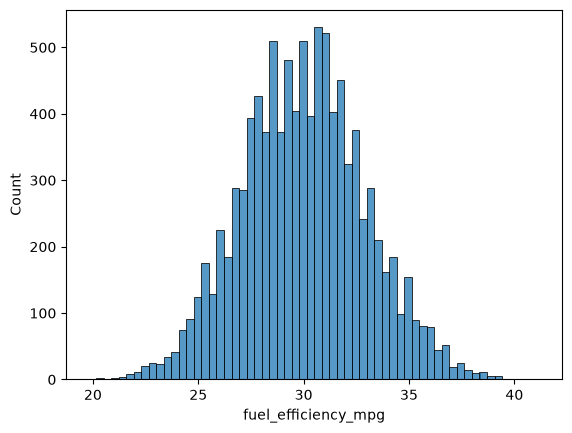

In [240]:
# EDA
# Look at the fuel_efficiency_mpg variable. Does it have a long tail?
sns.histplot(df.fuel_efficiency_mpg)

In [241]:
df.fuel_efficiency_mpg.skew()

np.float64(0.08080419601878173)

In [242]:
# So, no long tail.

## Question 1

There's one column with missing values. What is it?

In [243]:
df.columns[df.isna().any()]

Index(['horsepower'], dtype='str')

Answer: `'horsepower'`

## Question 2

What's the median (50% percentile) for variable `'horsepower'`?

In [244]:
df['horsepower'].median()

np.float64(254.0)

Answer: 254

## Prepare and split the dataset

Shuffle the filtered dataset and create the split

In [245]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [246]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [247]:
# We see above that the index contains the original row numbers. Let's reset it.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7


## Question 3

- We need to deal with missing values for the column from Q1.
- We have two options: fill it with 0 or with the mean of this variable.
- Try both options. For each, train a linear regression model without regularization using the code from the lessons.
- For computing the mean, use the training only!
- Use the validation dataset to evaluate the models and compare the RMSE of each option.
- Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
- Which option gives better RMSE?

Options:
- With 0
- With mean
- Both are equally good

In [248]:
y_train = np.array(df_train.fuel_efficiency_mpg)
y_val = np.array(df_val.fuel_efficiency_mpg)
y_test = np.array(df_test.fuel_efficiency_mpg)

In [249]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [250]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [251]:
def rmse(y, y_pred, decimals=3):
    se = (y - y_pred) ** 2
    mse = se.mean()
    score = np.sqrt(mse)
    if decimals is None or decimals is False:
        return score
    rounded_score = round(score, decimals)
    return rounded_score

In [252]:
df_train.columns

Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year'], dtype='str')

In [253]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
base

['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [254]:
X_train = df_train[base].values

In [255]:
w0 , w = train_linear_regression(X_train, y_train)

In [256]:
w0

np.float64(nan)

In [257]:
w

array([nan, nan, nan, nan])

In [258]:
# Both the bias term and the weights are "not a number". That's because we have missing values

In [259]:
df_train[base].isnull().sum()

engine_displacement      0
horsepower             538
vehicle_weight           0
model_year               0
dtype: int64

In [260]:
df_train_zeros = df_train[base].fillna(0)

In [261]:
df_train_zeros[base].isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [262]:
X_train_zeros = df_train_zeros.values

In [263]:
w0_zeros, w_zeros = train_linear_regression(X_train_zeros, y_train)

In [264]:
w0_zeros

np.float64(-153.8849618823138)

In [265]:
w_zeros

array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01])

In [266]:
y_pred_zeros = w0_zeros + X_train_zeros.dot(w_zeros)

<Axes: ylabel='Count'>

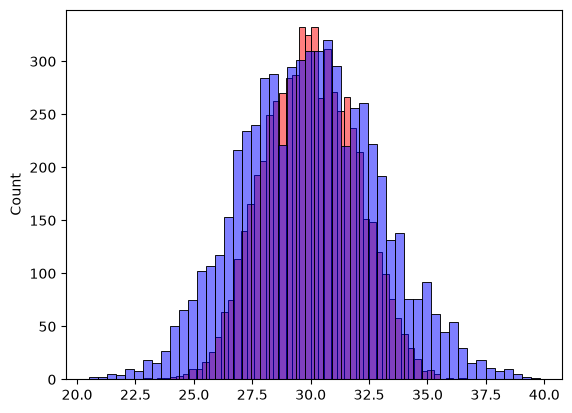

In [267]:
sns.histplot(y_pred_zeros, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [268]:
rmse_zeros = rmse(y_train, y_pred_zeros)
rmse_zeros

np.float64(2.2)

In [269]:
# Let's compute the RMSE, when filling the missing data with zeros, on the validation data
df_val[base].isnull().sum()

engine_displacement      0
horsepower             176
vehicle_weight           0
model_year               0
dtype: int64

In [270]:
df_val_zeros = df_val[base].fillna(0)
df_val_zeros[base].isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [271]:
X_val_zeros = df_val_zeros.values
y_val_pred_zeros = w0_zeros + X_val_zeros.dot(w_zeros)
rmse(y_val, y_val_pred_zeros)

np.float64(2.205)

In [272]:
# Now let's re-do the whole thing but filling the missing values with the mean instead of zeros

In [273]:
# First, I wanna know how many decimals it has
df_train['horsepower'].astype(str).str.split(".", expand=True)[1].str.len().max()

np.float64(1.0)

In [274]:
mean_of_horsepower = round(df_train.horsepower.mean(), 1)
mean_of_horsepower

np.float64(254.5)

In [275]:
# Let's make sure that we're dealing with what we expect: there should be empty values. Just making sure that we did not overwrite earlier something we shouldn't.
df_train[base].isnull().sum()

engine_displacement      0
horsepower             538
vehicle_weight           0
model_year               0
dtype: int64

In [276]:
df_train_mean = df_train[base].fillna(mean_of_horsepower)

In [277]:
df_train_mean[base].isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [278]:
X_train_mean = df_train_mean.values

In [279]:
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [280]:
w0_mean

np.float64(-153.29301159253492)

In [281]:
w_mean

array([-0.00102378, -0.00648722, -0.00388827,  0.10197729])

In [282]:
y_pred_mean = w0_mean + X_train_mean.dot(w_mean)

<Axes: ylabel='Count'>

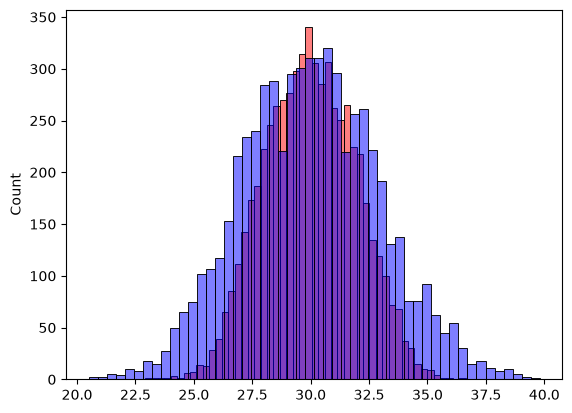

In [283]:
sns.histplot(y_pred_mean, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [284]:
rmse_mean = rmse(y_train, y_pred_mean)
rmse_mean

np.float64(2.198)

In [285]:
# Let's compute the RMSE, when filling the missing data with the mean, on the validation data
df_val[base].isnull().sum()

engine_displacement      0
horsepower             176
vehicle_weight           0
model_year               0
dtype: int64

In [286]:
df_val_mean = df_val[base].fillna(mean_of_horsepower)
df_val_mean[base].isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [287]:
X_val_mean = df_val_mean.values
y_val_pred_mean = w0_mean + X_val_mean.dot(w_mean)
rmse(y_val, y_val_pred_mean)

np.float64(2.202)

In [288]:
# So the RMSE when filling missing values with 0 was 2.205; but when filling missing values with the mean it gave us an RMSE of 2.202
# A smaller RMSE is better. Therefore, using the mean gave us a better RMSE.

Answer: With mean

## Question 4

- Now let's train a regularized linear regression.
- For this question, fill the NAs with 0.
- Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
- Use RMSE to evaluate the model on the validation dataset.
- Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
- Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:
- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100

In [289]:
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values


def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    score = rmse(y_val, X_val.dot(w) + w0, decimals=4)
    print(f"{r:<5} --> {score}")

0     --> 2.2053
0.01  --> 2.2058
0.1   --> 2.2241
1     --> 2.3492
5     --> 2.4094
10    --> 2.4195
100   --> 2.4292


In [290]:
# So the r that gives the best RMSE is 0

Answer: 0

## Question 5

- We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
- Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
- For each seed, do the train/validation/test split with 60%/20%/20% distribution.
- Fill the missing values with 0 and train a model without regularization.
- For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
- What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
- Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?
- 0.006
- 0.016
- 0.029
- 0.036
> Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. If it's high, the values are different. If standard deviation of scores is low, then our model is stable.

In [291]:
def split(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    return df_train, df_val, df_test


base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']


def prepare_X(df, fill_value):
    return df[base].fillna(fill_value).values


seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

scores = []

for seed in seeds:
    df5_train, df5_val, df5_test = split(df, seed)
    w0, w = train_linear_regression(prepare_X(df5_train, 0), df5_train.fuel_efficiency_mpg.values)
    score = rmse(df5_val.fuel_efficiency_mpg.values, prepare_X(df5_val, 0).dot(w) + w0, decimals=None)
    scores.append(score)

print(scores)
for seed, score in zip(seeds, scores):
    print(f"{seed} --> {score:.4f}")
round(np.std(scores), 3)

[np.float64(2.239204143046126), np.float64(2.2021128210838845), np.float64(2.1634197787530947), np.float64(2.2043588768539224), np.float64(2.2018800943311554), np.float64(2.2457851509085134), np.float64(2.2697212079524043), np.float64(2.190794599933443), np.float64(2.216611201686444), np.float64(2.2070365928178957)]
0 --> 2.2392
1 --> 2.2021
2 --> 2.1634
3 --> 2.2044
4 --> 2.2019
5 --> 2.2458
6 --> 2.2697
7 --> 2.1908
8 --> 2.2166
9 --> 2.2070


np.float64(0.029)

Answer: 0.029

## Question 6

- Split the dataset like previously, use seed 9.
- Combine train and validation datasets.
- Fill the missing values with 0 and train a model with `r=0.001`.
- What's the RMSE on the test dataset?

Options:
- 0.236
- 2.236
- 22.10
- 221.0

In [292]:
df6_train, df6_val, df6_test = split(df, 9)
df6_train_val = pd.concat([df6_train, df6_val])
y6_train_val = df6_train_val.fuel_efficiency_mpg.values

w0, w = train_linear_regression_reg(prepare_X(df6_train_val, 0), y6_train_val, r=0.001)
rmse(df6_test.fuel_efficiency_mpg, prepare_X(df6_test, 0).dot(w) + w0, decimals=3)

np.float64(2.236)

Answer: 2.236